# QSAR REGRESSION MODEL FOR NEUROTOXICITY

# Preparing The Environments

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Update PATH to point to your desired Google Drive folder
PATH = '/content/drive/MyDrive/'

Mounted at /content/drive


In [ ]:
!pip install -q rdkit

import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 42.2 MB/s eta 0:00:00


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/Neurotox/supporting_information_table_s1_tfaa016.xlsx')
display(df.head(7))

,No.,CAS,SMILES,pLD50
0,1,54-71-7,CCC1C(Cc2cncn2C)COC1=O,-2.190332
1,2,55-16-3,CN1C2CC(CC1C3OC23)OC(=O)C(CO)c4ccccc4,-2.017033
2,3,58-40-2,CN(C)CCCN1c2ccccc2Sc3ccccc13,-2.146128
3,4,60-25-3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392
4,5,69-27-2,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392
5,6,71-81-8,CC(C)[N+](C)(CCC(C(=O)N)(c1ccccc1)c2ccccc2)C(C)C,-2.079181
6,7,126-17-0,CC1CCC2(NC1)OC3CC4C5CC=C6CC(O)CCC6(C)C5CCC4(C)...,-2.953760


In [ ]:
# Remove both CAS and No. columns from both dataframes
df = df.drop(columns=['CAS', 'No.'], errors='ignore')
df_model_dev_sanitized = df_model_dev_sanitized.drop(columns=['CAS', 'No.'], errors='ignore')

# Display the cleaned dataframe head to verify
display(df_model_dev_sanitized.head())

,SMILES,pLD50,smi_no_salts,no_water
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,CCC1C(=O)OCC1Cc1cncn1C,CCC1C(=O)OCC1Cc1cncn1C
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,CN(C)CCCN1c2ccccc2Sc2ccccc21,CN(C)CCCN1c2ccccc2Sc2ccccc21
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,C[N+](C)(C)CCCCCC[N+](C)(C)C,C[N+](C)(C)CCCCCC[N+](C)(C)C
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1


# Exploratory Data Analysis

In [ ]:
 #Check rows and columns
print(df.shape)

# Check column names
print(df.columns)

# Check missing values
print(df.isnull().sum())

(422, 2)
Index(['SMILES', 'pLD50'], dtype='object')
SMILES    0
pLD50     0
dtype: int64


# Plot a histogram

<Axes: title={'center': 'Distribution of pLD50'}, ylabel='Frequency'>

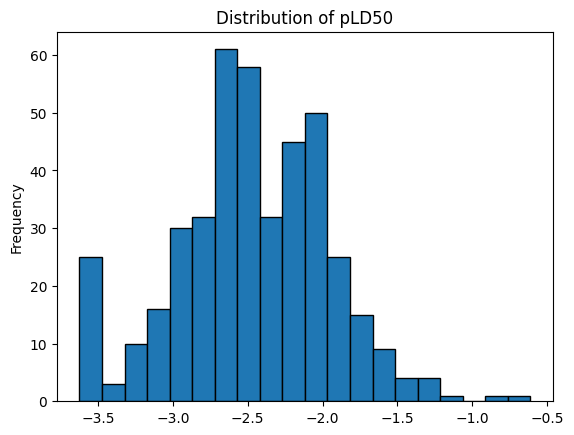

In [ ]:
# Plot a histogram of the neurotoxicity target variable (pLD50)
df['pLD50'].plot.hist(bins=20, edgecolor='black', title='Distribution of pLD50')

In [ ]:
#@title Function for sanitisation
##Create a function that takes a DataFrame, sanitises the SMILES, and returns a new DataFrame containing the SMILES and the endpoint

def sanitize_smiles(df):
    sanitized_smiles = []
    valid_indices = []

    for idx, row in df.iterrows():
        smi = row['SMILES']
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            # Convert back to canonical SMILES
            sanitized_smiles.append(Chem.MolToSmiles(mol))
            valid_indices.append(idx)

    # Create a new DataFrame with the sanitized SMILES and corresponding endpoint values
    df_new = df.loc[valid_indices].copy()
    df_new['SMILES'] = sanitized_smiles
    return df_new

#Apply the function to the DataFrame
df_model_dev_sanitized = sanitize_smiles(df)

[20:30:28] Explicit valence for atom # 0 Cl, 1, is greater than permitted


In [ ]:
#@title Remove the salts
from rdkit.Chem.SaltRemover import SaltRemover

# Instantiate the salt remover
remover = SaltRemover()

def remove_salts(smiles_str):
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is not None:
        res = remover.StripMol(mol)
        return Chem.MolToSmiles(res)
    return ""

# Apply salt removal to the sanitized dataset
df_model_dev_sanitized["smi_no_salts"] = df_model_dev_sanitized["SMILES"].apply(remove_salts)
display(df_model_dev_sanitized.head())

,SMILES,pLD50,smi_no_salts
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,CCC1C(=O)OCC1Cc1cncn1C
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,CN(C)CCCN1c2ccccc2Sc2ccccc21
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,C[N+](C)(C)CCCCCC[N+](C)(C)C
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1


In [ ]:
#@title Remove water molecules
def remove_water(smiles_str):
    # Water can be represented as 'O' or '[H]O[H]'
    if smiles_str == 'O' or smiles_str == '[H]O[H]':
        return ''
    return smiles_str

# Apply water removal
df_model_dev_sanitized["no_water"] = df_model_dev_sanitized["smi_no_salts"].apply(remove_water)

# Remove empty entries (fully stripped salts or water)
df_model_dev_sanitized = df_model_dev_sanitized[df_model_dev_sanitized["no_water"] != '']
display(df_model_dev_sanitized.head())

,SMILES,pLD50,smi_no_salts,no_water
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,CCC1C(=O)OCC1Cc1cncn1C,CCC1C(=O)OCC1Cc1cncn1C
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,CN(C)CCCN1c2ccccc2Sc2ccccc21,CN(C)CCCN1c2ccccc2Sc2ccccc21
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,C[N+](C)(C)CCCCCC[N+](C)(C)C,C[N+](C)(C)CCCCCC[N+](C)(C)C
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1


In [ ]:
#@title Select the molecules with invalid atoms
# Write your code here to create the non_allowed_indx list

allowed_atoms = {'H', 'C', 'N', 'O', 'P', 'S', 'Si', 'F', 'Cl', 'Br', 'I'}
non_allowed_indx = []

for idx, row in df_model_dev_sanitized.iterrows():
    smi = row['no_water']
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        # Check all atoms in the molecule
        for atom in mol.GetAtoms():
            symbol = atom.GetSymbol()
            if symbol not in allowed_atoms:
                non_allowed_indx.append(idx)
                break # Move to next molecule once a disallowed atom is found

print(f"Indices of molecules with disallowed atoms: {non_allowed_indx}")
print(f"Number of invalid molecules identified: {len(non_allowed_indx)}")

Indices of molecules with disallowed atoms: []
Number of invalid molecules identified: 0


In [ ]:
#@title Identify and remove mixtures

# Identify mixtures by checking if a dot '.' is present in the SMILES string
mixture_mask = df_model_dev_sanitized["no_water"].str.contains('\\.', regex=True)
num_mixtures = mixture_mask.sum()

# Filter out the mixtures
df_model_dev_sanitized = df_model_dev_sanitized[~mixture_mask]

# Reset index
df_model_dev_sanitized.reset_index(drop=True, inplace=True)

print(f"Number of mixture molecules removed: {num_mixtures}")
print(f"Remaining molecules in the dataset: {len(df_model_dev_sanitized)}")
display(df_model_dev_sanitized.head())

Number of mixture molecules removed: 0
Remaining molecules in the dataset: 421


,SMILES,pLD50,smi_no_salts,no_water
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,CCC1C(=O)OCC1Cc1cncn1C,CCC1C(=O)OCC1Cc1cncn1C
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,CN(C)CCCN1c2ccccc2Sc2ccccc21,CN(C)CCCN1c2ccccc2Sc2ccccc21
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,C[N+](C)(C)CCCCCC[N+](C)(C)C,C[N+](C)(C)CCCCCC[N+](C)(C)C
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1


In [ ]:
#@title Remove duplicate entries
# Find duplicates based on the finalized 'no_water' SMILES column
duplicate_mask = df_model_dev_sanitized.duplicated(subset=['no_water'], keep='first')
num_duplicates = duplicate_mask.sum()

# Drop duplicates, keeping the first occurrence
df_model_dev_sanitized = df_model_dev_sanitized[~duplicate_mask]

# Reset the index
df_model_dev_sanitized.reset_index(drop=True, inplace=True)

print(f"Number of duplicate molecules removed: {num_duplicates}")
print(f"Remaining unique molecules in the dataset: {len(df_model_dev_sanitized)}")
display(df_model_dev_sanitized.head())

Number of duplicate molecules removed: 0
Remaining unique molecules in the dataset: 421


,SMILES,pLD50,smi_no_salts,no_water
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332,CCC1C(=O)OCC1Cc1cncn1C,CCC1C(=O)OCC1Cc1cncn1C
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128,CN(C)CCCN1c2ccccc2Sc2ccccc21,CN(C)CCCN1c2ccccc2Sc2ccccc21
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392,C[N+](C)(C)CCCCCC[N+](C)(C)C,C[N+](C)(C)CCCCCC[N+](C)(C)C
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1


In [ ]:
#@title Saving the DataFrame to Google Drive
# Create the final clean DataFrame with only the curated SMILES and pLD50 (renamed to y)
df_model_dev_sanitized_clean = df_model_dev_sanitized[["no_water", "pLD50"]].copy()
df_model_dev_sanitized_clean.rename(columns={"no_water": "SMILES", "pLD50": "y"}, inplace=True)

display(df_model_dev_sanitized_clean.head())
print(f"Final clean dataset size: {df_model_dev_sanitized_clean.shape}")

# Save to Google Drive using the defined PATH variable
save_path = f"{PATH}clean_sanitized_neurotox_data.csv"
df_model_dev_sanitized_clean.to_csv(save_path, index=False)
print(f"Dataset successfully saved to: {save_path}")

,SMILES,y
0,CCC1C(=O)OCC1Cc1cncn1C,-2.190332
1,CN1C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12,-2.017033
2,CN(C)CCCN1c2ccccc2Sc2ccccc21,-2.146128
3,C[N+](C)(C)CCCCCC[N+](C)(C)C,-1.792392
4,C[N+](C)(C)CC[N+]1(C)Cc2c(Cl)c(Cl)c(Cl)c(Cl)c2C1,-1.792392


Final clean dataset size: (421, 2)
Dataset successfully saved to: /content/drive/MyDrive/Neurotox/clean_sanitized_neurotox_data.csv
